In [1]:
import os 
import sys

import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

from desilike.samples import Profiles, Chain, plotting
from cosmoprimo.fiducial import DESI

plt.style.use(os.path.join(os.path.abspath('../bin'), 'plot_style.mplstyle'))
plots_dir = '../../plots/'

%load_ext autoreload
%autoreload 2

In [2]:
template = 'FM'
tracers = ["BGS", "LRG1", "LRG2", "LRG3", "ELG2", "QSO", "joint"]
results_dir = '/global/cfs/cdirs/desi/users/mpinon/thetacut/{}'.format(template)

In [3]:
default_colors = {'BGS': 'yellowgreen', 'LRG1': 'orange', 'LRG2': 'orangered', 'LRG3': 'firebrick', 'ELG1': 'skyblue', 'ELG2': 'steelblue', 'QSO': 'seagreen', 'joint': 'black'}

In [4]:
cosmo = DESI()

truth = dict(qpar=1, qper=1, qiso=1, qap=1, dm=0, dn=0, df=1) | {
    "Omega_m": cosmo.Omega0_m,
    "logA": np.log(10**10 * cosmo.A_s),
    "sigma8_m": cosmo.sigma8_m,
    "h": cosmo.h,
    "H0": 100 * cosmo.h,
    "omega_cdm": cosmo["omega_cdm"],
    "omega_b": cosmo["omega_b"],
    "n_s": cosmo["n_s"],
    "w0_fld": -1.0,
    "wa_fld": 0.0,
    "sigmabao": 0.0,
    "syst_0": 0.0,
    "syst_1": 1.0,
}

In [5]:
def get_errors(chain, param):
    interval = tuple(_.item() for _ in chain.interval(param))
    lower, upper = interval
    mid = 0.5 * (lower + upper)
    yerr = [[upper - mid], [mid - lower]]
    return mid, yerr

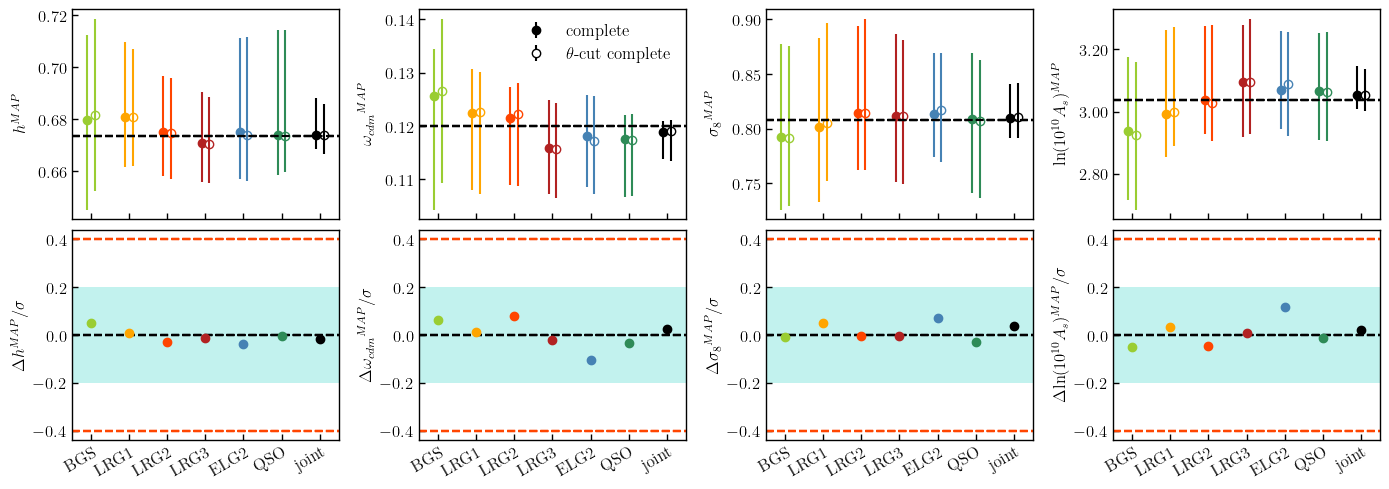

In [6]:
plt.rcParams["figure.autolayout"] = False
plt.rcParams["axes.grid"] = False

params = ['qiso', 'qap', 'dm', 'df'] if template=='SF' else ['h', 'omega_cdm', 'sigma8_m', 'logA']

fig, lax = plt.subplots(2, len(params), figsize=(14, 5), sharex=True, sharey=False, gridspec_kw={'height_ratios': [2, 2]})

stat = 'MAP'

for i, tracer in enumerate(tracers):
    chain_complete = Chain.concatenate([Chain.load(os.path.join(results_dir, 'chain_{}_thetacutFalse_{:d}.npz'.format(tracer, i))).remove_burnin(0.5)[::10] for i in range(8)])
    chain_complete_thetacut = Chain.concatenate([Chain.load(os.path.join(results_dir, 'chain_{}_thetacutTrue_{:d}.npz'.format(tracer, i))).remove_burnin(0.5)[::10] for i in range(8)])
    profile_complete = Profiles.load(os.path.join(results_dir, 'profile_{}_thetacutFalse.npy'.format(tracer)))
    profile_complete_thetacut = Profiles.load(os.path.join(results_dir, 'profile_{}_thetacutTrue.npy'.format(tracer)))
    
    for iparam, param in enumerate(params):
        if stat=='mean':
            map_complete = chain_complete.mean(param)
            map_complete_thetacut = chain_complete_thetacut.mean(param)
        elif stat=='MAP':
            map_complete = profile_complete.bestfit.choice()[param]
            map_complete_thetacut = profile_complete_thetacut.bestfit.choice()[param]
            
        mid_complete, yerr_complete = get_errors(chain_complete, param)
        mid_complete_thetacut, yerr_complete_thetacut = get_errors(chain_complete_thetacut, param)
             
        std_complete = chain_complete.std(param)
        std_complete_thetacut = chain_complete_thetacut.std(param)
        
        param_latex = chain_complete.params()[param].latex(inline=True)
 
        ax = lax[0][iparam]
        #ax.errorbar(i-0.1, map_complete, std_complete, marker='o', ls='', color=default_colors[tracer])
        #ax.errorbar(i+0.1, map_complete_thetacut, std_complete_thetacut, marker='o', ls='', markerfacecolor='white', color=default_colors[tracer])
        ax.plot(i-0.1, map_complete, marker='o', ls='', color=default_colors[tracer])
        ax.plot(i+0.1, map_complete_thetacut, marker='o', ls='', markerfacecolor='white', color=default_colors[tracer])
        ax.errorbar(i-0.1, mid_complete, yerr_complete, marker='', ls='', color=default_colors[tracer])
        ax.errorbar(i+0.1, mid_complete_thetacut, yerr_complete_thetacut, marker='', ls='', markerfacecolor='white', color=default_colors[tracer])
        ax.axhline(truth[param], color='black', ls='--')
        ax.set_ylabel(param_latex+(r'$^{MAP}$' if stat=='MAP' else ''))
        ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

        ax = lax[1][iparam]
        ax.plot(i, (map_complete_thetacut-map_complete)/std_complete_thetacut, marker='o', ls='', color=default_colors[tracer], zorder=10)
        ax.axhline(0, color='black', ls='--')
        ax.fill_between(np.arange(-1, len(tracers)+1), -0.2, 0.2, facecolor='turquoise', alpha=0.05)
        ax.axhline(0.4, color='C1', ls='--')
        ax.axhline(-0.4, color='C1', ls='--')
        #ax.set_ylim(-0.21, 0.21)
        
        ax.set_ylabel(r'$\Delta$'+param_latex+(r'$^{MAP}$' if stat=='MAP' else '')+r'$/\sigma$')
        
        ax.set_xticks(range(len(tracers)), tracers)
        ax.set_xticklabels(tracers, rotation=30, ha="right", va="top", rotation_mode="anchor")
    
    ax.set_xlim(-0.5, len(tracers)-0.5)
    
lax[0][1].errorbar([], [], [], marker='o', ls='', color='black', label='complete')
lax[0][1].errorbar([], [], [], marker='o', ls='', markerfacecolor='white', color='black', label=r'$\theta$-cut complete')
lax[0][1].legend()
    
fig = plt.gcf()
fig.align_ylabels()
plt.tight_layout()
plt.subplots_adjust(hspace=0.05, wspace=0.3)
#plt.savefig(os.path.join(plots_dir, 'AbacusSummit_v4_2_complete_corrected_thetacut_25mocks_{}_{}.pdf'.format(template, stat)), dpi=300)
plt.show()

In [7]:
sys.path.append('../bin')
from plot import *
from samples import *

fp_complete = FitProduct(chain=chain_complete, profile=profile_complete, minlike=None, resample=None)
fp_complete_thetacut = FitProduct(chain=chain_complete_thetacut, profile=profile_complete_thetacut, minlike=None, resample=None)

In [8]:
stat = 'MAP'

fp_complete_dict = {}
fp_complete_thetacut_dict = {}

for i, tracer in enumerate(tracers):
    chain_complete = Chain.concatenate([Chain.load(os.path.join(results_dir, 'chain_{}_thetacutFalse_{:d}.npz'.format(tracer, i))).remove_burnin(0.5)[::10] for i in range(8)])
    chain_complete_thetacut = Chain.concatenate([Chain.load(os.path.join(results_dir, 'chain_{}_thetacutTrue_{:d}.npz'.format(tracer, i))).remove_burnin(0.5)[::10] for i in range(8)])
    profile_complete = Profiles.load(os.path.join(results_dir, 'profile_{}_thetacutFalse.npy'.format(tracer)))
    profile_complete_thetacut = Profiles.load(os.path.join(results_dir, 'profile_{}_thetacutTrue.npy'.format(tracer)))

    fp_complete = FitProduct(chain=chain_complete, profile=profile_complete, minlike=None, resample=None)
    fp_complete_dict[tracer] = fp_complete

    fp_complete_thetacut = FitProduct(chain=chain_complete_thetacut, profile=profile_complete_thetacut, minlike=None, resample=None)
    fp_complete_thetacut_dict[tracer] = fp_complete_thetacut
    
fpc_complete = FitProductCollection(fp_complete_dict)
fpc_complete_thetacut = FitProductCollection(fp_complete_thetacut_dict)

In [9]:
import matplotlib
BLUE = matplotlib.cm.tab10.colors[0]

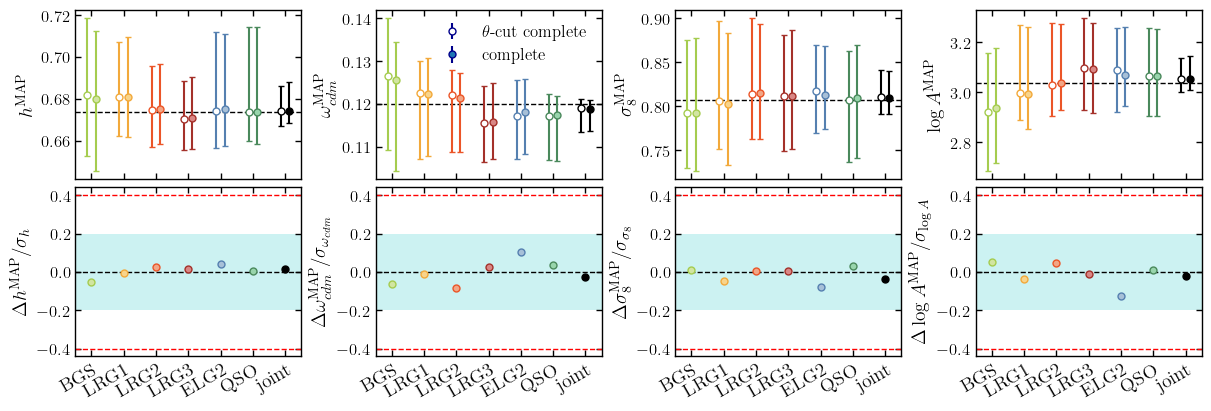

In [10]:
if template=='SF':
    fig, axes = shapefit_compare_bins(fpc = fpc_complete, fpc_ref = fpc_complete_thetacut)
elif template=='FM':
    fig, axes = fullmodel_compare_bins(fpc = fpc_complete, fpc_ref = fpc_complete_thetacut)
axes[0][1].errorbar([], [], yerr=[], ls='', label=r'$\theta$-cut complete', c='darkblue', capsize=2, marker="o", ms=5, mec='darkblue', mfc='white')
axes[0][1].errorbar([], [], yerr=[], ls='', label=r'complete', c='darkblue', capsize=2, marker="o", ms=5, mec='darkblue', mfc=BLUE)
axes[0][1].legend(fontsize=12)
plt.savefig(os.path.join(plots_dir, 'AbacusSummit_v4_2_complete_corrected_thetacut_25mocks_{}_{}.pdf'.format(template, stat)), dpi=300)
plt.show()